In [ ]:
#초급
import os
import sys
import time
import json
import urllib.request
import datetime

client_id = "YOUR_NAVER_CLIENT_ID"
client_secret = "YOUR_NAVER_CLIENT_SECRET"

#웹크롤링 메인함수
def main():
    node = 'news'
    srcText = input('검색어를 입력하세요:')
    cnt = 0
    jsonResult = []

#100번을 가져옴 그냥 정보자체를 100개 가져옴
    jsonResponse = getNaverSearch(node,srcText,1,100)
    total = jsonResponse['total']

#100개인지를 확인하기 위한 조건인듯 items 딕셔너리를 받아옴
    while((jsonResponse != None) and (jsonResponse['display']!=0)):
        for post in jsonResponse['items']:
            cnt += 1
            getPostData(post, jsonResult, cnt)
        start = jsonResponse['start'] + jsonResponse['display']
        if start > total or start > 1000:
            break
        jsonResponse = getNaverSearch(node, srcText, start, 100)
    print('전체 검색: %d 건' %total)

    with open('%s_naver_%s.json' % (srcText, node),'w',encoding = 'utf8') as outfile:
        jsonFile = json.dumps(jsonResult, indent =4, sort_keys = True, ensure_ascii = False)

        outfile.write(jsonFile)

    print("가져온 데이터: %d 건" %(cnt))
    print('%s_naver_%s.json SAVED' % (srcText,node))

def getRequestUrl(url):
    req = urllib.request.Request(url)
    req.add_header("X-Naver-Client-Id",client_id)
    req.add_header("X-Naver-Client-Secret",client_secret)
        
    #에러 났을때 로그를 남겨주는 부분 
    try:
        response = urllib.request.urlopen(req)
        if response.getcode() == 200:
            print("[%s] Url Request Success" % datetime.datetime.now())
            return response.read().decode('utf-8')
    except Exception as e:
        print(e)
        print("[%s] Error for URL:%s" % (datetime.datetime.now(),url))
        return None
    
def getPostData(post, jsonResult, cnt):
    title = post['title']
    description = post['description']
    org_link = post['originallink']
    link = post['link']

    pDate = datetime.datetime.strptime(post['pubDate'], '%a, %d %b %Y %H:%M:%S +0900')
    if pDate.date() == datetime.datetime.now().date():
        pDate = pDate.strftime('%Y-%m-%d %H:%M:%S')
        jsonResult.append({'cnt':cnt, 'title':title, 'description':description, 'org_link':org_link, 'link':org_link, 'pDate':pDate})
    return

#이게 그 네이버 뉴스 크롤링 api를 활용하는 방식이네 url 만드는법
#꼭 찾아서 들어가서 보고 플랫폼 마다 다름
def getNaverSearch(node,srcText, page_start, display):
    base = "https://openapi.naver.com/v1/search"
    node = "/%s.json" % node
    parameters = "?query=%s&start=%s&display=%s&sort=date" % (urllib.parse.quote(srcText),page_start,display)

    url = base + node + parameters
    responseDecode = getRequestUrl(url)

    if(responseDecode == None):
        return None
    else:
        return json.loads(responseDecode)
    

if __name__ == "__main__":
    main()

In [ ]:
#중급
import urllib.request
import json
import time
import datetime

client_id = "YOUR_NAVER_CLIENT_ID"
client_secret = "YOUR_NAVER_CLIENT_SECRET"

def main():
    node = 'news'
    a = {}
    for i in range(3):
        srcText = input('검색어를 입력하세요:')
        cnt = 0
        jsonResult = []

    #100번을 가져옴 그냥 정보자체를 100개 가져옴
        jsonResponse = getNaverSearch(node,srcText,1,100)
        total = jsonResponse['total']

        print('전체 검색: %d 건' %total)
        a[srcText] = total

    sorted_a = sorted(a.items(), key = lambda x: x[1] ,reverse = True )
    num = 0
    for k, t in sorted_a:
        print(f"{k}이(가) {t}개로 {num+1}번째")
        num += 1

def getRequestUrl(url):
    req = urllib.request.Request(url)
    req.add_header("X-Naver-Client-Id",client_id)
    req.add_header("X-Naver-Client-Secret",client_secret)
        

    try:
        response = urllib.request.urlopen(req)
        if response.getcode() == 200:
            print("[%s] Url Request Success" % datetime.datetime.now())
            return response.read().decode('utf-8')
    #에러 났을때 로그를 남겨주는 부분 
    except Exception as e:
        print(e)
        print("[%s] Error for URL:%s" % (datetime.datetime.now(),url))
        return None
    
def getNaverSearch(node,srcText, page_start, display):
    base = "https://openapi.naver.com/v1/search"
    node = "/%s.json" % node
    parameters = "?query=%s&start=%s&display=%s&sort=date" % (urllib.parse.quote(srcText),page_start,display)

    url = base + node + parameters
    responseDecode = getRequestUrl(url)

    if(responseDecode == None):
        return None
    else:
        return json.loads(responseDecode)
    
if __name__ == "__main__":
    main()


=============== 크롤링 완료 ===============
전체 검색: 21470 건
가져온 데이터: 1000 건
배고프다_naver_news.json SAVED

=== 최근 일자별 기사수 통계 ===
오늘 데이터수는 3
1일전 4 ,2일전 3 ,3일전 0 ,4일전 10 ,5일전 2 ,6일전 0 ,7일전 0

=== 24시간 시간대별 기사 분포 ===
0시 64개 /1시 12개 /2시 5개 /3시는 3개


4시 13개 /5시 14개 /6시 57개 /7시는 47개


8시 65개 /9시 64개 /10시 72개 /11시는 62개


12시 42개 /13시 42개 /14시 58개 /15시는 64개


16시 47개 /17시 47개 /18시 36개 /19시는 34개


20시 42개 /21시 46개 /22시 33개 /23시는 31개




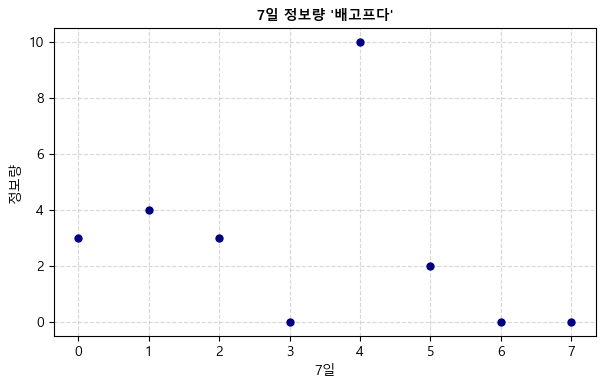

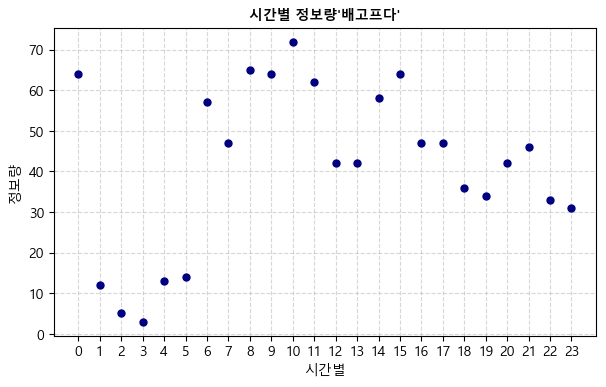

In [4]:
import os
import sys
import time
import json
import urllib.request
import datetime
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

client_id = "YOUR_NAVER_CLIENT_ID"
client_secret = "YOUR_NAVER_CLIENT_SECRET"

# 웹크롤링 메인함수
def main():
    node = 'news'
    srcText = input('검색어를 입력하세요:')
    cnt = 0
    jsonResult = []
    day7 = datetime.datetime.now().date() - datetime.timedelta(days=7)
    con7 = {}
    for i in range(8):
        con7[i] = 0

    t_24 = {}
    for i in range(24):
        t_24[i] = 0

    # 정보자체를 100개 가져옴
    jsonResponse = getNaverSearch(node, srcText, 1, 100)
    
    if jsonResponse is None:
        print("네이버 API 응답을 받지 못했습니다.")
        return
        
    total = jsonResponse['total']

    # 100개씩 반복 크롤링
    while ((jsonResponse != None) and (jsonResponse['display'] != 0)):
        for post in jsonResponse['items']:
            cnt += 1
            getPostData(post, jsonResult, cnt, con7, day7, t_24)
        start = jsonResponse['start'] + jsonResponse['display']
        if start > total or start > 1000:
            break
        jsonResponse = getNaverSearch(node, srcText, start, 100)
        
    print('\n' + '='*15 + ' 크롤링 완료 ' + '='*15)
    print('전체 검색: %d 건' % total)

    print("가져온 데이터: %d 건" % (cnt))
    print('%s_naver_%s.json SAVED' % (srcText, node))
    
    # 텍스트 통계 출력
    print('\n=== 최근 일자별 기사수 통계 ===')
    for i, k in con7.items():
        if i == 0:
            print(f"오늘 데이터수는 {k}")
        elif i == 7:
            print(f"{i}일전 {k}\n")
        else:
            print(f"{i}일전 {k}", end=" ,")
            
    print('=== 24시간 시간대별 기사 분포 ===')
    num = 1
    for i, k in t_24.items():
        if num % 4 != 0:
            print(f'{i}시 {k}개', end=' /')
        else:
            print(f'{i}시는 {k}개')
            print('\n')
        num += 1

    x_days = list(con7.keys())      # [0, 1, 2, 3, 4, 5, 6, 7]
    y_counts = list(con7.values())  # 각 일자별 기사 개수 리스트
    x_times = list(t_24.keys())
    y_times = list(t_24.values())

   #창크기
    plt.figure(figsize=(7, 4)) 
    
    plt.plot(x_days, y_counts, 'o', color='navy', markersize=5) 
    
    plt.title(f"7일 정보량 '{srcText}'", fontsize=10, fontweight='bold')
    plt.xlabel('7일')
    plt.ylabel('정보량')
    
    plt.xticks(x_days)
    
    plt.grid(True, linestyle='--', alpha=0.5)

    plt.show()

    plt.figure(figsize=(7, 4)) 
    
    plt.plot(x_times, y_times, 'o', color='navy', markersize=5) 
    
    plt.title(f"시간별 정보량'{srcText}'", fontsize=10, fontweight='bold')
    plt.xlabel('시간별')
    plt.ylabel('정보량')
    
    plt.xticks(x_times)
    

    plt.grid(True, linestyle='--', alpha=0.5)
    
    plt.show()

def getRequestUrl(url):
    req = urllib.request.Request(url)
    req.add_header("X-Naver-Client-Id", client_id)
    req.add_header("X-Naver-Client-Secret", client_secret)
        
    try:
        response = urllib.request.urlopen(req)
        if response.getcode() == 200:
            return response.read().decode('utf-8')
    except Exception as e:
        print(e)
        print("[%s] Error for URL:%s" % (datetime.datetime.now(), url))
        return None
    
def getPostData(post, jsonResult, cnt, con7, day7, t_24):
    title = post['title']
    description = post['description']
    org_link = post['originallink']
    link = post['link']

    pDate = datetime.datetime.strptime(post['pubDate'], '%a, %d %b %Y %H:%M:%S +0900')
    pDate_1 = pDate.strftime('%Y-%m-%d %H:%M:%S')
    t_pDate = pDate_1.split(' ')
    t_hour = t_pDate[1].split(':')[0]
    t_hour = int(t_hour)
    t_24[t_hour] += 1
    
    if pDate.date() > day7:
        cai = (datetime.datetime.now().date() - pDate.date()).days
        pDate = pDate.strftime('%Y-%m-%d %H:%M:%S')
        con7[cai] += 1
        jsonResult.append({'cnt': cnt, 'title': title, 'description': description, 'org_link': org_link, 'link': org_link, 'pDate': pDate})
    return

def getNaverSearch(node, srcText, page_start, display):
    base = "https://openapi.naver.com/v1/search"
    node = "/%s.json" % node
    parameters = "?query=%s&start=%s&display=%s&sort=date" % (urllib.parse.quote(srcText), page_start, display)

    url = base + node + parameters
    responseDecode = getRequestUrl(url)

    if (responseDecode == None):
        return None
    else:
        return json.loads(responseDecode)

if __name__ == "__main__":
    main()

In [1]:
import matplotlib.font_manager as fm
fm.fontManager.ttflist 
[f.name for f in fm.fontManager.ttflist]

['STIXSizeFourSym',
 'STIXSizeThreeSym',
 'DejaVu Serif',
 'STIXSizeFourSym',
 'DejaVu Serif',
 'STIXGeneral',
 'DejaVu Sans',
 'STIXNonUnicode',
 'DejaVu Sans Mono',
 'DejaVu Sans Mono',
 'STIXSizeTwoSym',
 'DejaVu Sans Mono',
 'STIXSizeTwoSym',
 'STIXSizeFiveSym',
 'DejaVu Sans',
 'cmsy10',
 'STIXGeneral',
 'STIXSizeOneSym',
 'STIXNonUnicode',
 'STIXSizeThreeSym',
 'cmb10',
 'STIXNonUnicode',
 'DejaVu Serif',
 'DejaVu Sans',
 'cmmi10',
 'cmtt10',
 'STIXGeneral',
 'DejaVu Sans Mono',
 'DejaVu Sans Display',
 'STIXSizeOneSym',
 'DejaVu Sans',
 'cmr10',
 'cmex10',
 'cmss10',
 'DejaVu Serif',
 'STIXGeneral',
 'STIXNonUnicode',
 'DejaVu Serif Display',
 'Harrington',
 'Courier New',
 'Segoe UI',
 'Verdana',
 'Impact',
 'Bell MT',
 'Berlin Sans FB',
 'UD Digi Kyokasho N',
 'Arial',
 'Consolas',
 'NanumGothic',
 'Lucida Sans',
 'Franklin Gothic Heavy',
 'HYGungSo-Bold',
 'Bodoni MT',
 'Georgia',
 'Malgun Gothic',
 'Papyrus',
 'Noto Serif KR',
 'Times New Roman',
 'Goudy Stout',
 'Pyunji R',

In [ ]:
import urllib.request, datetime, time, json, pandas as pd

ServiceKey = "YOUR_DATA_GO_KR_KEY"

def getRequestUrl(url): #[CODE 1]
    req = urllib.request.Request(url)
    try:
        response = urllib.request.urlopen(req)
        if response.getcode() == 200 :
            print("[%s] Url Request Success" % datetime.datetime.now())
            return response.read().decode('utf-8')
    except Exception as e:
        print(e)
        print("[%s] Error for URL : %s" % (datetime.datetime.now(), url))
        return None 
    
def getTourismStatsItem(yyyymm, nat_cd, ed_cd):
    service_url = "http://openapi.tour.go.kr/openapi/service/EdrcntTourismStatsService/getEdrcntTourismStatsList"
    parameters = "?_type=json&serviceKey=" + ServiceKey #인증키
    parameters += "&YM=" + yyyymm
    parameters += "&NAT_CD=" + nat_cd  
    parameters += "&ED_CD=" + ed_cd

    url = service_url + parameters
    print(url) # 액세스 거부 여부 확인용 출력
    responseDecode = getRequestUrl(url) #[CODE 1]

    if (responseDecode == None):
        return None
    else:
        return json.loads(responseDecode)
    
def getTourismStatsService(nat_cd, ed_cd, nStartYear, nEndYear):
    jsonResult = []
    result = []
    natName = ''
    dataEND = "{0}{1:0>2}".format(str(nEndYear), str(12))
    isDataEnd = 0 #데이터 끝 확인용 flag 초기화
    for year in range(nStartYear, nEndYear+1):
        for month in range(1, 13):
            if(isDataEnd == 1): break #수집기간이 남았어도 데이터 끝이면 작업 중지.
            yyyymm = "{0}{1:0>2}".format(str(year), str(month))
            jsonData = getTourismStatsItem(yyyymm, nat_cd, ed_cd) #[CODE 2]
            if (jsonData['response']['header']['resultMsg'] == 'OK'):
                if jsonData['response']['body']['items'] == '' : #데이터가 없는 마지막 항목인 경우
                    isDataEnd = 1
                    if (month-1) == 0 : #마지막 데이터가 12월인데, 현재 month가 다음해 1월인 경우, year와 month변수 값 조정
                        year = year-1
                        month = 13
                    dataEND = "{0}{1:0>2}".format(str(year), str(month-1))
                    print("데이터 없음.... \n제공되는 통계 데이터는 %s년 %s월까지입니다." %(str(year), str(month-1)))
                    jsonData = getTourismStatsItem(dataEND, nat_cd, ed_cd) # 출력용으로 마지막 데이터 다시 호출
                    break
                print(json.dumps(jsonData, indent=4, sort_keys=True, ensure_ascii=False))
                
                natName = jsonData['response']['body']['items']['item' ]['natKorNm']
                natName = natName.replace(' ', '')
                num = jsonData['response']['body']['items']['item']['num']
                ed = jsonData['response']['body']['items']['item']['ed']
                print('[ %s_%s : %s ]' %(natName, yyyymm, num))
                print('-' * 70)
                jsonResult.append({'nat_name': natName, 'nat_cd': nat_cd, 'yyyymm': yyyymm, 'visit_cnt': num})
                result.append([natName, nat_cd, yyyymm, num])
                print('<마지막 jsonData>\n', json.dumps(jsonData, indent=4, sort_keys=True, ensure_ascii=False)) #마지막 jsonData를 확인용으로 출력

    return (jsonResult, result, natName, dataEND)

def main(): #[CODE 0]
    jsonResult = []
    result = []
    natName=''

    print("<< 국내 입국한 외국인의 통계 데이터를 수집합니다. >>")
    nat_cd = input('국가 코드를 입력하세요(중국: 112 / 일본: 130 / 미국: 275) :')
    nStartYear = int(input('데이터를 몇 년부터 수집할까요? : '))
    nEndYear = int(input('데이터를 몇 년까지 수집할까요? : '))
    ed_cd = "E" #E : 방한외래관광객, D : 해외 출국

    jsonResult, result, natName, dataEND = getTourismStatsService(nat_cd, ed_cd, nStartYear, nEndYear) #[CODE 3]
    if (natName==''): # URL 요청은 성공하였지만, 데이터 제공이 안 된 경우
        print(' 데이터가 전달되지 않았습니다. 공공데이터포털의 서비스 상태를 확인하기바랍니다.')
    else:
        #파일저장 1 : json 파일
        with open('./%s_%s_%d_%s.json' % (natName, nat_cd, nStartYear, dataEND), 'w', encoding='utf8') as outfile :
            jsonFile = json.dumps(jsonResult, indent = 4, sort_keys = True, ensure_ascii = False)
            outfile.write(jsonFile)
        #파일저장 2 : csv 파일
        columns = ["입국자국가", "국가코드", "입국연월", "입국자 수"]
        result_df = pd.DataFrame(result, columns = columns)
        result_df.to_csv('./%s_%s_%d_%s.csv' % (natName, nat_cd, nStartYear, dataEND), index = False, encoding = 'cp949')

if __name__ == '__main__':
    main()

<< 국내 입국한 외국인의 통계 데이터를 수집합니다. >>
http://openapi.tour.go.kr/openapi/service/EdrcntTourismStatsService/getEdrcntTourismStatsList?_type=json&serviceKey=SC-SD-CE-IC-001&YM=202401&NAT_CD=112&ED_CD=E
[2026-05-22 14:50:28.590210] Url Request Success
http://openapi.tour.go.kr/openapi/service/EdrcntTourismStatsService/getEdrcntTourismStatsList?_type=json&serviceKey=SC-SD-CE-IC-001&YM=202402&NAT_CD=112&ED_CD=E
[2026-05-22 14:50:29.615475] Url Request Success
http://openapi.tour.go.kr/openapi/service/EdrcntTourismStatsService/getEdrcntTourismStatsList?_type=json&serviceKey=SC-SD-CE-IC-001&YM=202403&NAT_CD=112&ED_CD=E
[2026-05-22 14:50:29.658910] Url Request Success
http://openapi.tour.go.kr/openapi/service/EdrcntTourismStatsService/getEdrcntTourismStatsList?_type=json&serviceKey=SC-SD-CE-IC-001&YM=202404&NAT_CD=112&ED_CD=E
[2026-05-22 14:50:30.670106] Url Request Success
http://openapi.tour.go.kr/openapi/service/EdrcntTourismStatsService/getEdrcntTourismStatsList?_type=json&serviceKey=SC-SD-CE-IC

In [ ]:
def main():
    jsonResult = []
    result = []
    natName =''
    print("<<국내 입국한 외국인의 통계 데이터를 수집합니다.>>")
    nat_cd = input('국가 코드를 입력하세요(중국: 112 / 일본: 130 / 미국: 275):')
    nStartYear = int(input('데이터를 몇 년부터 수집할까요?:'))
    nEndYear = int(input('데이터를 몇 년까지 수집할까요? :'))
    ed_cd = "E"

    jsonResult, result, natName, dataEND = getTourismStatsService(nat_cd, ed_cd, nStartYear, nEndYear)
    if(natName == ""):
        print('데이터가 전달되지 않았습니다. 공공데이터포털의 서비스 상태를 확인하기 바랍니다.')
    else:
        with open('./%s_%s_%d_%s.json' % (natName, ed_cd, nStartYear, dataEND),'w',encoding='utf8') as outfile:
            jsonFile = json.dumps(jsonResult, indent = 4, sort_keys = True, ensure_ascii = False)
            outfile.write(jsonFile)

            columns = ["입국자국가","국가코드","입국연월","입국자 수"]
            result_df = pd.DataFrame(result,columns = colums)
            result_df.to_csv('./%s_%s_%d_%s.csv' % (natName, ed_cd, nStartYear, dataEND), index = False, encoding = 'cp949')

def getRequestUrl(url):
    req = urllib.request.Request(url)
    try:
        response = urllib.request.urlopen(req)
        if response.getcode() == 200:
            print("[%s] Url Request Success" % datetime.datetime.now())
            return response.read().decode('utf-8')
    except Exception as e:
        print(e)
        print("[%s] Error for URL: %s"%(datetime.datetime.now(), url))
        return None
def getTourismStatsItem(yyyymm, nat_cd, ed_cd):
    service_url = "http://openapi.tour.go.kr/openapi/servicee/EdrcntTourismStatsService/getEdrcntTourismStatsList"
    parameters= "?_type=json&serviceKey=" + 'YOUR_DATA_GO_KR_KEY'
    parameters += "&YM=" +yyyymm
    parameters += "&NAT_CD=" + nat_cd
    parameters += "&EC_CD=" + ed_cd

    url = service_url + parameters
    print(url)
    responseDecode = getRequestUrl(url)

    if(responseDecode == None):
        return None
    else:
        return json.loads(responseDecode)
    
def getTourismStatsService(nat_cd, ed_cd, nStartYear, nEndYear):
    jsonResult = []
    result = []
    natName = ''
    dataEnd = "{0}{1:0>2}".format(str(nEndYear),str(12))
    isDataEnd = 0
    for year in range(nStartYear, nEndYear+1):    
        for month in range(1, 13):
            if(isDataEnd == 1): break #수집기간이 남았어도 데이터 끝이면 작업 중지.
        yyyymm = "{0}{1:0>2}".format(str(year), str(month))
        jsonData = getTourismStatsItem(yyyymm, nat_cd, ed_cd) #[CODE 2]
        if (jsonData['response']['header']['resultMsg'] = = 'OK'):
            if jsonData['response']['body']['items'] == '' :  #데이터가 없는 마지막 항목인 경우
                isDataEnd = 1
                if (month-1) == 0 :  #마지막 데이터가 12월인데, 현재 month가 다음해 1월인 경우, year와 month변수 값 조정
                    Year = year-1
                month = 13
            dataEND = "{0}{1:0>2}".format(str(year), str(month-1))
            print("데이터 없음.... \n제공되는 통계 데이터는 %s년 %s월까지입니다."  %(str(year), str(month-1)))
            jsonData = getTourismStatsItem(dataEND, nat_cd, ed_cd)  # 출력용으로 마지막 데이터 다시 호출
            break
            natName = jsonData['response']['body']['items']['item' ]['natKorNm']
            natName = natName.replace(' ', '')
            num = jsonData['response']['body']['items']['item']['num’]
            ed = jsonData['response']['body']['items']['item']['ed’]
            print('[ %s_%s : %s ]' %(natName, yyyymm, num))
            print(‘-’ * 70)
            jsonResult.append({'nat_name': natName, 'nat_cd': nat_cd, 'yyyymm': yyyymm, 'visit_cnt': num})
            result.append([natName, nat_cd, yyyymm, num])
            print('<마지막 jsonData>\n', json.dumps(jsonData, indent=4, sort_keys=True, ensure_ascii=False)) #마지막 jsonData를 확인용으로 출력
return (jsonResult, result, natName, ed, dataEND)

SyntaxError: unterminated string literal (detected at line 73) (3837460268.py, line 73)

In [ ]:
import datetime
import json
import pandas as pd
import urllib.request


def main():
    jsonResult = []
    result = []
    natName = ""
    print("<<국내 입국한 외국인의 통계 데이터를 수집합니다.>>")
    nat_cd = input("국가 코드를 입력하세요(중국: 112 / 일본: 130 / 미국: 275): ")
    nStartYear = int(input("데이터를 몇 년부터 수집할까요?: "))
    nEndYear = int(input("데이터를 몇 년까지 수집할까요? : "))
    ed_cd = "E"

    jsonResult, result, natName, ed, dataEND = getTourismStatsService(
        nat_cd, ed_cd, nStartYear, nEndYear
    )

    if natName == "":
        print(
            "데이터가 전달되지 않았습니다. 공공데이터포털의 서비스 상태나 입력값을 확인하기 바랍니다."
        )
    else:
        # JSON 파일 저장
        with open(
            "./%s_%s_%d_%s.json" % (natName, ed, nStartYear, dataEND),
            "w",
            encoding="utf8",
        ) as outfile:
            jsonFile = json.dumps(
                jsonResult, indent=4, sort_keys=True, ensure_ascii=False
            )
            outfile.write(jsonFile)

        # CSV 파일 저장 (colums -> columns 오타 수정)
        columns = ["입국자국가", "국가코드", "입국연월", "입국자 수"]
        result_df = pd.DataFrame(result, columns=columns)
        result_df.to_csv(
            "./%s_%s_%d_%s.csv" % (natName, ed, nStartYear, dataEND),
            index=False,
            encoding="cp949",
        )
        print(f"\n<< {natName} 데이터 수집 및 파일 저장 완료! >>")


def getRequestUrl(url):
    req = urllib.request.Request(url)
    try:
        response = urllib.request.urlopen(req)
        if response.getcode() == 200:
            print("[%s] Url Request Success" % datetime.datetime.now())
            return response.read().decode("utf-8")
    except Exception as e:
        print(e)
        print("[%s] Error for URL: %s" % (datetime.datetime.now(), url))
        return None


def getTourismStatsItem(yyyymm, nat_cd, ed_cd):
    service_url = "http://openapi.tour.go.kr/openapi/service/EdrcntTourismStatsService/getEdrcntTourismStatsList"
    parameters = (
        "?_type=json&serviceKey="
        + "YOUR_DATA_GO_KR_KEY"
    )
    parameters += "&YM=" + yyyymm
    parameters += "&NAT_CD=" + nat_cd
    parameters += "&ED_CD=" + ed_cd

    url = service_url + parameters
    responseDecode = getRequestUrl(url)

    if responseDecode is None:
        return None
    else:
        return json.loads(responseDecode)

#main 함수에서 인수 4개 받아서 호출됨
def getTourismStatsService(nat_cd, ed_cd, nStartYear, nEndYear):
    jsonResult = []
    result = []
    #natName, ed 는 다 초기화
    natName = ""
    ed = ""
    #끝나는 날을 해당년도에 12월로 저장함
    dataEND = "{0}{1:0>2}".format(str(nEndYear), str(12))
    #끝나는 flag설정
    isDataEnd = 0

    for year in range(nStartYear, nEndYear + 1):
        for month in range(1, 13):
            if isDataEnd == 1:
                break

            yyyymm = "{0}{1:0>2}".format(str(year), str(month))
            jsonData = getTourismStatsItem(yyyymm, nat_cd, ed_cd)

            if (
                #일단 통신은 성공했는지 if문으로 확인
                jsonData and jsonData["response"]["header"]["resultMsg"] == "OK"):
                #통신은 성공했는데 데이터가 비어있으면 데이터를 마지막까지 읽었다고 판단
                if ( jsonData["response"]["body"]["items"] == "" or not jsonData["response"]["body"]["items"]):
                    isDataEnd = 1
                    #1월 달이면 1년을 깎고
                    if month - 1 == 0:
                        dataEND = "{0}{1:0>2}".format(str(year - 1), str(12))
                    #그 외에는 월을 깍아서 마지막 달을 저장함
                    else:
                        dataEND = "{0}{1:0>2}".format(
                            str(year), str(month - 1)
                        )

                    print(f"데이터 없음.... \n제공되는 통계 데이터는 {str(year)}년 {str(month-1)}월까지입니다.")
                    break
                #item에 있는 데이터 꺼내오기
                natName = jsonData["response"]["body"]["items"]["item"]['natKorNm']
                #데이터 주변의 공백을 다 제거함
                natName = natName.replace(' ','')
                num = jsonData["response"]["body"]["items"]["item"]['num']
                ed = jsonData['response']['body']['items']['item']['ed']
                print("[%s_%s : %s]" % (natName, yyyymm, num))
                print("-" * 70)

                #json 파일용으로 저장
                jsonResult.append(
                    {
                        "nat_name": natName,
                        "nat_cd": nat_cd,
                        "yyyymm": yyyymm,
                        "visit_cnt": num,
                    }
                )
                #csv 파일용으로 저장
                result.append([natName, nat_cd, yyyymm, num])
        #1월에서 12월 다 돌면 break 하고 다음년도로 넘어감
        if isDataEnd == 1:
            break
    #main함수로 변수 5개값 돌려주면서 끝
    return (jsonResult, result, natName, ed, dataEND)


# 스크립트 실행부
if __name__ == "__main__":
    main()

<<국내 입국한 외국인의 통계 데이터를 수집합니다.>>
[2026-05-22 16:28:33.929440] Url Request Success
[중국_202001 : 481681]
----------------------------------------------------------------------
[2026-05-22 16:28:34.989627] Url Request Success
[중국_202002 : 104086]
----------------------------------------------------------------------
[2026-05-22 16:28:36.018060] Url Request Success
[중국_202003 : 16595]
----------------------------------------------------------------------
[2026-05-22 16:28:36.080935] Url Request Success
[중국_202004 : 3935]
----------------------------------------------------------------------
[2026-05-22 16:28:37.071847] Url Request Success
[중국_202005 : 5124]
----------------------------------------------------------------------
[2026-05-22 16:28:37.121381] Url Request Success
[중국_202006 : 5051]
----------------------------------------------------------------------
[2026-05-22 16:28:38.118579] Url Request Success
[중국_202007 : 9738]
--------------------------------------------------------------